# Gold news and monthly sentiment

## 1. Objective and data source

**Research question:** Can market regime detection and financial news sentiment analysis improve dynamic commodity portfolio allocation?

This notebook prepares a monthly gold-news feature for later use with Brent crude oil, natural gas, gold, silver and copper. It uses existing human annotations and stops at descriptive analysis and validation. Incremental information beyond price and macroeconomic features is a hypothesis to test subsequently.

The source is the [SaguaroCapital dataset card](https://huggingface.co/datasets/SaguaroCapital/sentiment-analysis-in-commodity-market-gold/blob/4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5/README.md), a Hugging Face redistribution of the [Sinha–Khandait Kaggle dataset](https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-in-commodity-market-gold). The revision is pinned below; the card lists a CC BY-NC-ND 4.0 licence. Its classification `train` and `test` splits are combined; they are not chronological investment samples.

[Sinha and Khandait (2020), §2.1](https://arxiv.org/html/2009.04202) describe expert annotation of headlines from financial publishers and aggregators, with disagreements resolved by consensus. Direction flags can overlap and describe past or expected price movements. The paper's corpus and the later redistribution differ in size and stated coverage; the audit below establishes the downloaded sample rather than assuming equivalence.

`Dates`, `URL` and `News` identify each record. The binary fields describe upward, unchanged and downward prices, asset comparison, and past/future information. `Price Sentiment` is the supplied categorical label. The card does not specify its exact conversion from the direction flags. We check that relationship empirically: `neutral` denotes unchanged-price sentiment, whereas `none` denotes no assigned price sentiment, not a missing label.

The existing **April 2006–December 2018** window is retained: April 2006 is Notebook 03's common-feature start; December 2018 is the chosen news cutoff, not the source's final observation. No window is selected using portfolio performance.

**Execution:** run top to bottom in Python 3 with `pandas`, `numpy`, `matplotlib`, `datasets` and `IPython`. Tested package versions are printed below. If needed, install in the kernel with `%pip install pandas==2.3.3 matplotlib==3.10.9 datasets==4.8.4`. The first load needs internet access; Hugging Face may reuse its standard cache. No API key, intermediate CSV or external script is required.

In [1]:
import sys
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
from datasets import load_dataset, disable_progress_bars

disable_progress_bars()
DATASET_ID = "SaguaroCapital/sentiment-analysis-in-commodity-market-gold"
DATASET_REVISION = "4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5"
START, END = pd.Timestamp("2006-04-01"), pd.Timestamp("2018-12-31")
MONTHS = pd.period_range(START, END, freq="M")
LABELS = ["positive", "negative", "neutral", "none"]
DIRECTION_COLUMNS = [
    "Price Direction Up", "Price Direction Constant", "Price Direction Down"
]
BINARY_COLUMNS = DIRECTION_COLUMNS + [
    "Asset Comparision", "Past Information", "Future Information"
]
ANNOTATION_COLUMNS = ["label"] + BINARY_COLUMNS
KEYS = ["date", "headline_key"]

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.2,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Python:", sys.version.split()[0])
print("Packages:", {p: version(p) for p in
                    ["pandas", "numpy", "matplotlib", "datasets", "ipython"]})

Python: 3.12.6
Packages: {'pandas': '2.3.3', 'numpy': '2.4.4', 'matplotlib': '3.10.9', 'datasets': '4.8.4', 'ipython': '8.30.0'}


## 2. Data loading and quality audit

Preserve source fields and parse dates strictly as day-month-year. Failed parses become `NaT` only for auditing and exclusion; no date is reconstructed. Strip surrounding whitespace from headlines and labels, and lowercase labels. For duplicate detection only, lowercase headlines and collapse repeated whitespace; punctuation and numbers remain intact. Counts below are recomputed from the pinned source on every run.

In [2]:
splits = load_dataset(DATASET_ID, revision=DATASET_REVISION)
raw = pd.concat(
    [part.to_pandas().assign(source_split=name) for name, part in splits.items()],
    ignore_index=True,
)
source_columns = [c for c in raw.columns if c != "source_split"]
required = {"Dates", "URL", "News", "Price Sentiment", *BINARY_COLUMNS}
assert required.issubset(raw.columns), f"Missing fields: {required - set(raw.columns)}"
assert len(raw) > 0, "Empty source dataset"

raw["date"] = pd.to_datetime(
    raw["Dates"].astype("string").str.strip(), format="%d-%m-%Y", errors="coerce"
)
raw["headline"] = raw["News"].astype("string").str.strip()
raw["label"] = raw["Price Sentiment"].astype("string").str.strip().str.lower()
raw["headline_key"] = (
    raw["headline"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
)

print("Source revision:", DATASET_REVISION)
display(raw.groupby("source_split").size().rename("rows").to_frame())
field_audit = pd.DataFrame({
    "dtype": raw[source_columns].dtypes.astype(str),
    "nulls": raw[source_columns].isna().sum(),
    "empty_strings": [raw[c].astype("string").str.strip().eq("").sum()
                      for c in source_columns],
})
display(field_audit)
print(f"Downloaded rows: {len(raw):,}")
print("Parsed date range:", raw["date"].min().date(), "to", raw["date"].max().date())
print("Invalid or missing dates:", int(raw["date"].isna().sum()))
print("Unexpected nonempty labels:",
      raw.loc[raw["label"].notna() & raw["label"].ne("")
              & ~raw["label"].isin(LABELS), "label"].value_counts().to_dict())
invalid_dates = raw.loc[raw["date"].isna(), ["Dates", "News", "source_split"]].copy()
display(invalid_dates.head(5))  # Full excluded records remain inspectable in memory.

Source revision: 4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5


,rows
source_split,
test,2114
train,8456


,dtype,nulls,empty_strings
Dates,object,0,0
URL,object,0,0
News,object,0,0
Price Direction Up,int64,0,0
Price Direction Constant,int64,0,0
Price Direction Down,int64,0,0
Asset Comparision,int64,0,0
Past Information,int64,0,0
Future Information,int64,0,0
Price Sentiment,object,0,0


Downloaded rows: 10,570
Parsed date range: 2000-02-15 to 2019-02-01
Invalid or missing dates: 165
Unexpected nonempty labels: {}


,Dates,News,source_split
185,0200-09-21,dec. gold moves up by $1.60 to $587.80/oz afte...,train
510,0200-04-28,"gold futures fall, hold recent trading range",train
511,0201-04-14,"gold, oil hold on to gains post bernanke",train
585,0201-03-21,"April gold up $5.50, or 0.5%, to $1,239.50/oz ...",train
700,0200-04-19,june gold up $7.90 at $631.20/oz after $632.70...,train


In [3]:
def duplicate_audit(frame):
    """Audit one record per normalized date–headline, without resolving conflicts."""
    groups = frame.groupby(KEYS, sort=False)
    sizes = groups.size()
    conflicts = groups[ANNOTATION_COLUMNS].nunique(dropna=False).gt(1).any(axis=1)
    conflict_keys = conflicts.index[conflicts]
    counts = {
        "rows": len(frame),
        "duplicate_groups": int(sizes.gt(1).sum()),
        "rows_in_duplicate_groups": int(sizes[sizes.gt(1)].sum()),
        "excess_duplicate_rows": int((sizes - 1).sum()),
        "conflicting_groups": len(conflict_keys),
        "rows_in_conflicting_groups": int(sizes.loc[conflict_keys].sum()),
    }
    return counts, conflict_keys

# Undated or empty-headline rows cannot define a usable date–headline key.
valid_keys = (raw["date"].notna() & raw["headline"].notna()
              & raw["headline"].ne(""))
raw_duplicate_counts, _ = duplicate_audit(raw.loc[valid_keys])
print("Exact duplicate source date–headline rows (excess):",
      int(raw.duplicated(["Dates", "News"]).sum()))
display(pd.Series(raw_duplicate_counts, name="all_valid_keys").to_frame())

# Binary-field validity is reported independently of categorical-label validity.
binary_audit = pd.DataFrame({
    "nulls": raw[BINARY_COLUMNS].isna().sum(),
    "nonbinary_nonmissing": ((~raw[BINARY_COLUMNS].isin([0, 1]))
                             & raw[BINARY_COLUMNS].notna()).sum(),
})
display(binary_audit)

Exact duplicate source date–headline rows (excess): 0


,all_valid_keys
rows,10405
duplicate_groups,1
rows_in_duplicate_groups,2
excess_duplicate_rows,1
conflicting_groups,0
rows_in_conflicting_groups,0


,nulls,nonbinary_nonmissing
Price Direction Up,0,0
Price Direction Constant,0,0
Price Direction Down,0,0
Asset Comparision,0,0
Past Information,0,0
Future Information,0,0


## 3. Cleaning and validation

Exclude undated records, dates outside the fixed window, empty headlines and missing/empty labels, with disjoint exclusion counts. Malformed strings such as `0200-09-21` cannot be assigned to a year reliably; their study-window membership is unknown. Excluding them may affect coverage.

Reject unexpected study labels or nonbinary annotations. Exclude every row of a duplicate key if **any supplied annotation** differs; otherwise retain its first occurrence. This avoids arbitrarily choosing between conflicting labels. The rule counts a same-day headline once even if repeated across URLs; different days remain separate. Multiple direction flags within one headline are audited separately and are not automatically errors or grounds for exclusion. Supplied sentiment labels are never replaced.

In [4]:
remaining = pd.Series(True, index=raw.index)
exclusions = {}
checks = [
    ("invalid_or_missing_date", raw["date"].isna()),
    ("outside_study_window", ~raw["date"].between(START, END)),
    ("missing_or_empty_headline", raw["headline"].isna() | raw["headline"].eq("")),
    ("missing_or_empty_label", raw["label"].isna() | raw["label"].eq("")),
]
for reason, mask in checks:
    removed = remaining & mask.fillna(False)
    exclusions[reason] = int(removed.sum())
    remaining &= ~removed

candidate = raw.loc[remaining].copy()
assert not candidate.empty, "No eligible headlines"
assert candidate["label"].isin(LABELS).all(), "Unexpected study-period label"
assert candidate[BINARY_COLUMNS].isin([0, 1]).all().all(), "Invalid study annotations"

study_duplicate_counts, conflict_keys = duplicate_audit(candidate)
conflict = pd.MultiIndex.from_frame(candidate[KEYS]).isin(conflict_keys)
conflicting_news = candidate.loc[conflict].copy()
nonconflicting = candidate.loc[~conflict]
news = nonconflicting.drop_duplicates(KEYS).sort_values("date", kind="stable").copy()
news["month"] = news["date"].dt.to_period("M")
exclusions["conflicting_duplicate_rows"] = int(conflict.sum())
exclusions["repeated_consistent_rows"] = len(nonconflicting) - len(news)

assert len(raw) == sum(exclusions.values()) + len(news), "Row reconciliation failed"
assert not news.empty and not news.duplicated(KEYS).any()
assert news["date"].between(START, END).all()
assert news[["date", "headline", "label"]].notna().all().all()
assert news["headline"].ne("").all() and news["label"].isin(LABELS).all()
display(pd.Series({**exclusions, "retained": len(news)}, name="rows").to_frame())
display(pd.DataFrame({"all_valid_keys": raw_duplicate_counts,
                      "study_before_deduplication": study_duplicate_counts}))
print("Retained daily coverage:", news["date"].min().date(), "to", news["date"].max().date())

,rows
invalid_or_missing_date,165
outside_study_window,1007
missing_or_empty_headline,0
missing_or_empty_label,0
conflicting_duplicate_rows,0
repeated_consistent_rows,1
retained,9397


,all_valid_keys,study_before_deduplication
rows,10405,9398
duplicate_groups,1,1
rows_in_duplicate_groups,2,2
excess_duplicate_rows,1,1
conflicting_groups,0,0
rows_in_conflicting_groups,0,0


Retained daily coverage: 2006-04-03 to 2018-12-28


In [5]:
label_distribution = pd.DataFrame({
    "source_count": raw["label"].value_counts().reindex(LABELS, fill_value=0),
    "retained_count": news["label"].value_counts().reindex(LABELS, fill_value=0),
})
label_distribution["source_share"] = label_distribution["source_count"] / len(raw)
label_distribution["retained_share"] = label_distribution["retained_count"] / len(news)
display(label_distribution.round(4))

# Inspect the complete joint distribution; binary directions need not be exclusive.
pattern_columns = DIRECTION_COLUMNS + ["label"]
annotation_patterns = pd.concat({
    "source_count": raw.groupby(pattern_columns, dropna=False).size(),
    "retained_count": news.groupby(pattern_columns, dropna=False).size(),
}, axis=1).fillna(0).astype(int)
display(annotation_patterns)

consistency_rows = []
for population, frame in [("source", raw), ("retained", news)]:
    up, constant, down = (frame[c].eq(1) for c in DIRECTION_COLUMNS)
    supported = (
        (frame["label"].eq("positive") & up)
        | (frame["label"].eq("negative") & down)
        | (frame["label"].eq("neutral") & constant)
        | (frame["label"].eq("none") & frame[DIRECTION_COLUMNS].eq(0).all(axis=1))
    ).fillna(False)
    # A diagnostic inference, not a documented conversion rule or relabelling step.
    priority_label = pd.Series(
        np.select([up, down, constant], ["positive", "negative", "neutral"], default="none"),
        index=frame.index,
    )
    consistency_rows.append({
        "population": population,
        "unsupported_or_missing_labels": int((~supported).sum()),
        "multiple_direction_flags": int(frame[DIRECTION_COLUMNS].sum(axis=1).gt(1).sum()),
        "up_and_down_flags": int((up & down).sum()),
        "mismatch_with_up_down_constant_priority": int(frame["label"].ne(priority_label).fillna(True).sum()),
    })
display(pd.DataFrame(consistency_rows).set_index("population"))
print("Retained temporal annotations (not mutually exclusive):")
display(news.groupby(["Past Information", "Future Information"]).size().rename("headlines").to_frame())

,source_count,retained_count,source_share,retained_share
label,,,,
positive,4412,3879,0.4174,0.4128
negative,3814,3382,0.3608,0.3599
neutral,376,348,0.0356,0.037
none,1968,1788,0.1862,0.1903


source_count  \
Price Direction Up Price Direction Constant Price Direction Down label                    
0                  0                        0                    none              1968   
                                            1                    negative          3783   
                   1                        0                    neutral            376   
                                            1                    negative            31   
1                  0                        0                    positive          4277   
                                            1                    positive            98   
                   1                        0                    positive            37   

                                                                           retained_count  
Price Direction Up Price Direction Constant Price Direction Down label                     
0                  0                        0                    none                1788  
                                            1                    negative            3351  
                   1                        0                    neutral              348  
                                            1                    negative              31  
1                  0                        0                    positive            3757  
                                            1                    positive              88  
                   1                        0                    positive              34

,unsupported_or_missing_labels,multiple_direction_flags,up_and_down_flags,mismatch_with_up_down_constant_priority
population,,,,
source,0,166,98,0
retained,0,153,88,0


Retained temporal annotations (not mutually exclusive):


headlines
Past Information Future Information           
0                1                         310
1                0                        9086
                 1                           1

## 4. Monthly sentiment construction

Assign +1 to `positive`, −1 to `negative`, and 0 to `neutral` and `none`, retaining the latter as separate classes in the count table. For observation month $t$,

$$
S_t=\frac{N_t^{+}-N_t^{-}}{N_t^{\mathrm{all}}},\qquad
D_t=\frac{N_t^{+}+N_t^{-}}{N_t^{\mathrm{all}}},\qquad
N_t^{\mathrm{all}}=N_t^{+}+N_t^{-}+N_t^{\mathrm{neutral}}+N_t^{\mathrm{none}}.
$$

This aggregation is our definition, not an estimator specified by the source authors. $S_t$ measures the balance of assigned positive and negative gold-price statements across **all retained headlines**; $D_t$ is the share assigned a directional sentiment label, not the share with any active binary direction flag. A small $S_t$ can reflect balanced directions or many zero-contribution headlines. More `none` or `neutral` observations dilute the balance.

News may summarize market narratives and attention absent from price and macroeconomic features, but may also repeat information already in prices. Neither $S_t$ nor $D_t$ is an expected return or evidence of predictive value. Months with no retained news receive a zero count and undefined ratios; they are reported and cause the coverage assertions to fail, rather than being filled with neutral sentiment.

In [6]:
label_counts = pd.crosstab(news["month"], news["label"])
label_counts = label_counts.reindex(index=MONTHS, columns=LABELS, fill_value=0)
n_all = label_counts.sum(axis=1)
denominator = n_all.where(n_all.gt(0))

monthly_news = pd.DataFrame(index=MONTHS)
monthly_news["gold_news_sentiment"] = (
    label_counts["positive"] - label_counts["negative"]
).div(denominator)
monthly_news["gold_news_count"] = n_all
monthly_news["gold_news_directional_share"] = (
    label_counts["positive"] + label_counts["negative"]
).div(denominator)

# Dates label the observation month; no information lag is applied here.
monthly_news.index = MONTHS.to_timestamp(how="start")
monthly_news.index.name = "date"
monthly_news = monthly_news.asfreq("MS")
missing_months = MONTHS[n_all.eq(0)]
print(f"Observed months: {int(n_all.gt(0).sum())} / {len(MONTHS)}")
print("Missing months:", missing_months.astype(str).tolist())
display(monthly_news.head().round(4))

Observed months: 153 / 153
Missing months: []


,gold_news_sentiment,gold_news_count,gold_news_directional_share
date,,,
2006-04-01,0.5143,35,0.8000
2006-05-01,0.2609,46,0.9130
2006-06-01,0.1053,38,0.7368
2006-07-01,0.0000,26,0.7692
2006-08-01,-0.3750,32,0.8125


In [7]:
expected_index = pd.date_range(START, END, freq="MS", name="date")
assert isinstance(monthly_news.index, pd.DatetimeIndex)
assert monthly_news.index.is_monotonic_increasing
assert monthly_news.index.is_unique
assert monthly_news.index.equals(expected_index), "Unexpected monthly coverage"
assert monthly_news.index.is_month_start.all() and monthly_news.index.freqstr == "MS"
assert len(missing_months) == 0, "Unobserved months: review coverage; do not impute sentiment"
assert monthly_news.notna().all().all(), "Missing output values"
assert np.isfinite(monthly_news.to_numpy()).all(), "Nonfinite output values"
assert monthly_news["gold_news_count"].gt(0).all()
assert pd.api.types.is_integer_dtype(monthly_news["gold_news_count"])
assert monthly_news["gold_news_count"].sum() == len(news)
assert monthly_news["gold_news_sentiment"].between(-1, 1).all()
assert monthly_news["gold_news_directional_share"].between(0, 1).all()
assert (monthly_news["gold_news_sentiment"].abs()
        <= monthly_news["gold_news_directional_share"] + 1e-12).all()
np.testing.assert_array_equal(
    label_counts.sum().reindex(LABELS).to_numpy(),
    news["label"].value_counts().reindex(LABELS, fill_value=0).to_numpy(),
)

# Independent row-score aggregation checks the formula AND observation-month alignment.
score = news["label"].map({"positive": 1, "negative": -1, "neutral": 0, "none": 0})
row_check = pd.DataFrame({
    "month": news["month"], "score": score,
    "directional": news["label"].isin(["positive", "negative"]).astype(int),
}).groupby("month").agg(sentiment=("score", "mean"), count=("score", "size"),
                       directional_share=("directional", "mean")).reindex(MONTHS)
row_check.index = MONTHS.to_timestamp(how="start")
assert row_check.index.equals(monthly_news.index)
np.testing.assert_allclose(monthly_news.to_numpy(), row_check.to_numpy(), rtol=0, atol=1e-12)
print("PASS: calendar, uniqueness, completeness, counts, ranges, formula and unshifted alignment.")

PASS: calendar, uniqueness, completeness, counts, ranges, formula and unshifted alignment.


## 5. Descriptive analysis

The table describes equally weighted months; the pooled headline balance weights months by their news counts. These are different summaries. The figure pairs sentiment with its denominator so that sparse months and changing coverage remain visible. Headline counts measure this corpus, not the total volume of gold news.

In [8]:
display(monthly_news.describe().round(3))
pooled_balance = (news["label"].eq("positive").sum()
                  - news["label"].eq("negative").sum()) / len(news)
past_share = news["Past Information"].eq(1).mean()
future_share = news["Future Information"].eq(1).mean()
counts = monthly_news["gold_news_count"]
sentiment = monthly_news["gold_news_sentiment"]
display(Markdown(
    f"**Executed sample:** {len(news):,} retained headlines across {len(monthly_news)} months; "
    f"{len(missing_months)} missing months. Monthly counts range from {counts.min():,} to "
    f"{counts.max():,} (median {counts.median():.0f}). Sentiment ranges from "
    f"{sentiment.min():.3f} to {sentiment.max():.3f}; its monthly mean is "
    f"{sentiment.mean():.3f}, versus a pooled headline balance of {pooled_balance:.3f}. "
    f"Past-information flags occur in {past_share:.1%} of retained headlines and "
    f"future-information flags in {future_share:.1%}; the flags can overlap. "
    "The predominance of past-oriented news limits a forward-looking interpretation."
))

,gold_news_sentiment,gold_news_count,gold_news_directional_share
count,153.000,153.000,153.000
mean,0.073,61.418,0.794
std,0.206,47.740,0.113
min,-0.381,14.000,0.518
25%,-0.060,29.000,0.720
50%,0.067,44.000,0.802
75%,0.227,69.000,0.875
max,0.533,250.000,1.000


**Executed sample:** 9,397 retained headlines across 153 months; 0 missing months. Monthly counts range from 14 to 250 (median 44). Sentiment ranges from -0.381 to 0.533; its monthly mean is 0.073, versus a pooled headline balance of 0.053. Past-information flags occur in 96.7% of retained headlines and future-information flags in 3.3%; the flags can overlap. The predominance of past-oriented news limits a forward-looking interpretation.

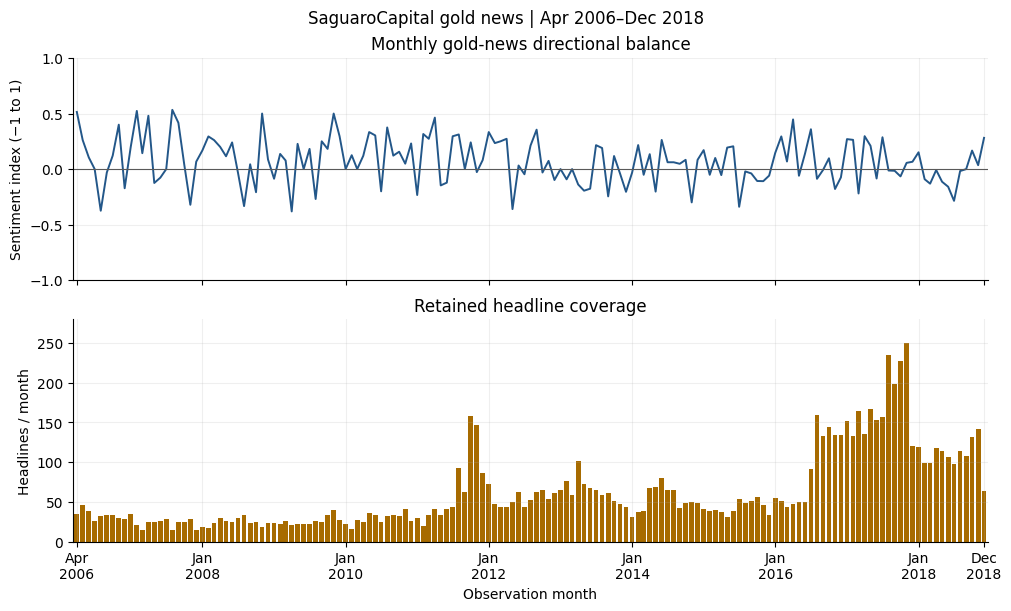

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout="constrained")
axes[0].plot(monthly_news.index, sentiment, color="#235789", linewidth=1.4)
axes[0].axhline(0, linewidth=0.8, color="0.35")
axes[0].set(title="Monthly gold-news directional balance", ylabel="Sentiment index (−1 to 1)",
            ylim=(-1, 1))
axes[1].bar(monthly_news.index, counts, width=24, color="#A76B00")
axes[1].set(title="Retained headline coverage", ylabel="Headlines / month",
            xlabel="Observation month", ylim=(0, counts.max() * 1.12))
ticks = [monthly_news.index[0], *pd.date_range("2008-01-01", "2018-01-01", freq="2YS"),
         monthly_news.index[-1]]
axes[1].set_xticks(ticks)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[1].set_xlim(monthly_news.index[0] - pd.Timedelta(days=20),
                 monthly_news.index[-1] + pd.Timedelta(days=20))
fig.suptitle(f"SaguaroCapital gold news | {START:%b %Y}–{END:%b %Y}", fontsize=12)
plt.show()

## 6. Integration readiness and limitations

**Confirmed implementation:** `monthly_news` has a month-start observation index named `date`, with `gold_news_sentiment`, `gold_news_count` and `gold_news_directional_share`. It is **unshifted**. Join it to market-regime inputs by their original observation month. Notebook 03 already uses `LAG = 2` and a calendar cutoff `decision_month - DateOffset(months=2)`; the later portfolio engine must apply that lag only once.

**Timing assumption:** a full month-$t$ aggregate cannot be known at the start of month $t$. For example, May 2016 news remains indexed **2016-05-01**, becomes potentially computable after May closes (assuming prompt collection and annotation), and can be used for a **July 2016** allocation under Notebook 03's convention. The month-start label is not a release timestamp. Actual historical collection and annotation availability are unverified.

In [10]:
# Illustrative timing check only: no feature values or index are shifted.
observation_month = pd.Timestamp("2016-05-01")
example = news.loc[news["month"].eq(observation_month.to_period("M"))]
example_counts = example["label"].value_counts().reindex(LABELS, fill_value=0)
example_sentiment = (example_counts["positive"] - example_counts["negative"]) / len(example)
assert np.isclose(monthly_news.loc[observation_month, "gold_news_sentiment"], example_sentiment)
display(pd.DataFrame({
    "observation_month": [observation_month],
    "after_month_close_earliest_calendar_date": [observation_month + pd.offsets.MonthBegin(1)],
    "illustrative_allocation_month": [observation_month + pd.DateOffset(months=2)],
    "headlines": [len(example)],
    "gold_news_sentiment": [example_sentiment],
}))

,observation_month,after_month_close_earliest_calendar_date,illustrative_allocation_month,headlines,gold_news_sentiment
0,2016-05-01,2016-06-01,2016-07-01,50,-0.06


**Limitations and later work.** The downloaded annotations are retrospective. A historical headline date does not establish that its text, label or complete monthly corpus was available then; a two-month lag cannot cure this point-in-time limitation. Missing publication times, changing source coverage, invalid-date exclusions, repeated reporting across different headlines, and ambiguous multi-direction statements may affect the series. The observed label/flag patterns are consistent with an up-before-down-before-constant priority, but the card does not document that rule; retaining supplied labels preserves the source's choices rather than validating their economic meaning. `none` is distinct from a missing value and must remain in the denominator.

The chosen news window ends before Notebook 03's 2021–2025 portfolio test. It therefore cannot be added directly to that test or extrapolated into it. Later integration requires an explicitly justified common historical sample and chronological evaluation, or additional comparably documented news data. Any comparison should hold timing, allocation rules and evaluation dates constant; it must not select the sentiment definition by future performance. No forecasting, clustering or portfolio experiment is performed here, and no predictive or portfolio-improvement claim follows from these descriptive results.